# 03 | Portfolio Analysis

Input: `organized_credit_data.csv`  |  Outputs: portfolio, segment, and WOE/IV tables

,segment_level,loan_intent,person_home_ownership,records,defaults,default_rate
1,loan_intent,DEBTCONSOLIDATION,All,5189,1488,0.287
4,loan_intent,MEDICAL,All,6042,1617,0.268
3,loan_intent,HOMEIMPROVEMENT,All,3594,940,0.262
5,loan_intent,PERSONAL,All,5498,1094,0.199
2,loan_intent,EDUCATION,All,6411,1106,0.173
6,loan_intent,VENTURE,All,5682,844,0.149
15,loan_intent_home,HOMEIMPROVEMENT,RENT,1533,665,0.434
8,loan_intent_home,DEBTCONSOLIDATION,OWN,71,28,0.394
9,loan_intent_home,DEBTCONSOLIDATION,RENT,2803,1004,0.358
18,loan_intent_home,MEDICAL,RENT,3414,1097,0.321


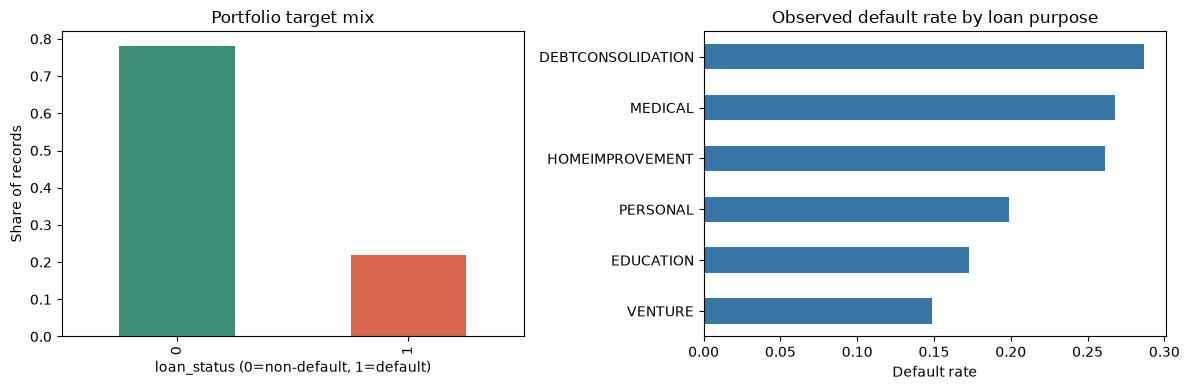

,feature,information_value
3,loan_grade,0.879
6,loan_percent_income,0.708
4,loan_int_rate,0.619
9,person_income,0.461
8,person_home_ownership,0.375
1,cb_person_default_on_file,0.164
5,loan_intent,0.096
2,loan_amnt,0.074
7,person_emp_length,0.060
0,cb_person_cred_hist_length,0.004


Saved portfolio segments and WOE/IV tables to powerbi_exports.


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "credit_risk_dataset.csv").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the project folder containing credit_risk_dataset.csv.")
source = project_root / "organized_credit_data.csv"
if not source.exists():
    raise FileNotFoundError("Run 01_data_cleaning.ipynb and 02_data_organization.ipynb first.")

data = pd.read_csv(source)
target = "loan_status"

portfolio_by_intent = data.groupby("loan_intent", dropna=False).agg(
    records=(target, "size"), defaults=(target, "sum"), default_rate=(target, "mean")
).reset_index()
portfolio_by_intent["segment_level"] = "loan_intent"
portfolio_by_intent["person_home_ownership"] = "All"

portfolio_by_home = data.groupby(
    ["loan_intent", "person_home_ownership"], dropna=False
).agg(records=(target, "size"), defaults=(target, "sum"), default_rate=(target, "mean")).reset_index()
portfolio_by_home = portfolio_by_home[portfolio_by_home["records"] >= 30].copy()
portfolio_by_home["segment_level"] = "loan_intent_home"

overall = pd.DataFrame(
    [
        {
            "loan_intent": "All",
            "person_home_ownership": "All",
            "records": len(data),
            "defaults": int(data[target].sum()),
            "default_rate": float(data[target].mean()),
            "segment_level": "overall",
        }
    ]
)
portfolio_segments = pd.concat(
    [overall, portfolio_by_intent, portfolio_by_home], ignore_index=True
)[
    ["segment_level", "loan_intent", "person_home_ownership", "records", "defaults", "default_rate"]
]
portfolio_segments = portfolio_segments.sort_values(
    ["segment_level", "default_rate"], ascending=[True, False]
)
display(portfolio_segments.head(20).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data[target].value_counts(normalize=True).sort_index().plot(
    kind="bar", ax=axes[0], color=["#3c8d78", "#d8644b"]
)
axes[0].set(
    title="Portfolio target mix",
    xlabel="loan_status (0=non-default, 1=default)",
    ylabel="Share of records",
)
portfolio_by_intent.sort_values("default_rate").plot(
    kind="barh", x="loan_intent", y="default_rate", ax=axes[1], legend=False, color="#3976a8"
)
axes[1].set(title="Observed default rate by loan purpose", xlabel="Default rate", ylabel="")
plt.tight_layout()
plt.show()

def make_bins(series, max_bins=5):
    if pd.api.types.is_numeric_dtype(series) and series.nunique(dropna=True) > 1:
        return pd.qcut(
            series,
            q=min(max_bins, series.nunique(dropna=True)),
            duplicates="drop",
        ).astype("string").fillna("Missing")
    return series.astype("string").fillna("Missing")


def woe_iv_table(frame, feature):
    work = pd.DataFrame({"bin": make_bins(frame[feature]), "target": frame[target]})
    table = work.groupby("bin", observed=False).agg(
        records=("target", "size"), defaults=("target", "sum")
    )
    table["non_defaults"] = table["records"] - table["defaults"]
    smooth = 0.5
    table["default_share"] = (table["defaults"] + smooth) / (
        table["defaults"].sum() + smooth * len(table)
    )
    table["non_default_share"] = (table["non_defaults"] + smooth) / (
        table["non_defaults"].sum() + smooth * len(table)
    )
    table["woe"] = np.log(table["non_default_share"] / table["default_share"])
    table["iv_component"] = (
        table["non_default_share"] - table["default_share"]
    ) * table["woe"]
    table["observed_default_rate"] = table["defaults"] / table["records"]
    table["feature"] = feature
    return table.reset_index()


features = [
    "person_income",
    "person_emp_length",
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_default_on_file",
    "cb_person_cred_hist_length",
]
woe_iv_detail = pd.concat(
    [woe_iv_table(data, feature) for feature in features], ignore_index=True
)
iv_summary = (
    woe_iv_detail.groupby("feature", as_index=False)["iv_component"]
    .sum()
    .rename(columns={"iv_component": "information_value"})
    .sort_values("information_value", ascending=False)
)
display(iv_summary.round(3))

output = project_root / "powerbi_exports"
output.mkdir(exist_ok=True)
portfolio_segments.to_csv(output / "portfolio_segments.csv", index=False)
woe_iv_detail.to_csv(output / "woe_iv_detail.csv", index=False)
print("Saved portfolio segments and WOE/IV tables to powerbi_exports.")